<a href="https://colab.research.google.com/github/ounissinour/PolypVision/blob/main/milestone1/M1_Reproduce.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 1 – Reproduce PraNet and Polyp-PVT

**PolypVision** · Nour Ounissi (RSPN69), Taha Mersni (K1TO74), Baha Amar (ZXQA2V)

Goal: run the official implementations and trained models of
[PraNet](https://github.com/DengPingFan/PraNet) (CNN, MICCAI 2020) and
[Polyp-PVT](https://github.com/DengPingFan/Polyp-PVT) (transformer, 2023) on the five standard
polyp test sets and check that we get the mean Dice / mean IoU printed in the papers
(target: 0.808 mean Dice for Polyp-PVT on CVC-ColonDB).

This notebook is self-contained: it needs only a GPU runtime (a T4 is enough) and internet access.
About 15 minutes end to end, most of it downloads.

| Step | What happens |
|---|---|
| 1 | Settings, packages, clone the two official repositories at fixed commits |
| 2 | Download the test data and the trained weights (Google Drive links from the two READMEs) |
| 3 | Patch the official test scripts (`scipy.misc.imsave` → `cv2.imwrite`, …) and run them |
| 4 | Evaluate the prediction maps with `pysodmetrics` (same definition as the papers' MATLAB toolbox) |
| 5 | Evaluator check on the authors' own published maps, comparison with the paper tables, figures |

## 1. Settings

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch
print("torch", torch.__version__, "cuda", torch.cuda.is_available())

name, memory.total [MiB]
Tesla T4, 15360 MiB
torch 2.11.0+cu130 cuda True


`USE_DRIVE = True` keeps the downloaded zips, weights and the outputs in your Google Drive, so a
second run skips the downloads. Data and prediction maps always stay on the Colab disk: unzipping
thousands of small files onto the Drive mount is slow and can stop half-way.

In [2]:
import os

PRANET_COMMIT = "95f12bd4e32ec954b5069654abae7de9473fd1f5"   # official PraNet repo, pinned
PVT_COMMIT = "cd71fbf9fcd8c32cc0f33699f4e0186073c64dc4"      # official Polyp-PVT repo, pinned
USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/polyp-m1"
else:
    WORK = "/content/work"
DATA = "/content/data"      # unzipped datasets
MAPS = "/content/maps"      # prediction maps of both models
OUT = "/content/m1"         # results and figures of this run

for d in [WORK, DATA, MAPS, f"{OUT}/results/authors_maps_check", f"{OUT}/figures"]:
    os.makedirs(d, exist_ok=True)
os.environ.update(WORK=WORK, DATA=DATA, MAPS=MAPS, OUT=OUT)   # so the shell cells can use them too
print("work folder:", WORK)

Mounted at /content/drive
work folder: /content/drive/MyDrive/polyp-m1


In [3]:
!pip install -q gdown pysodmetrics timm tabulate

Clone the two official repositories at fixed commits, so the run is the same every time.

In [4]:
%cd /content
!rm -rf PraNet Polyp-PVT
!git clone -q https://github.com/DengPingFan/PraNet && git -C PraNet checkout -q $PRANET_COMMIT
!git clone -q https://github.com/DengPingFan/Polyp-PVT && git -C Polyp-PVT checkout -q $PVT_COMMIT
!git -C PraNet log -1 --format='PraNet    %h %cd' && git -C Polyp-PVT log -1 --format='Polyp-PVT %h %cd'

/content
PraNet    95f12bd Thu Dec 11 13:11:43 2025 +1100
Polyp-PVT cd71fbf Wed Nov 1 14:41:31 2023 +0800


## 2. Download data and trained models

Everything comes from the Google Drive links in the two official READMEs, fetched with `gdown`:

| File | Content | From |
|---|---|---|
| `TestDataset.zip` | Kvasir 100, CVC-ClinicDB 62, CVC-ColonDB 380, ETIS-LaribPolypDB 196, CVC-300 60 images + masks | PraNet README |
| `TrainDataset.zip` | Kvasir-SEG 900 + CVC-ClinicDB 550 (not needed here, kept for Milestone 2) | PraNet README |
| `PraNet-19.pth` | PraNet trained weights | PraNet README |
| `PolypPVT.pth` | Polyp-PVT trained weights | Polyp-PVT README §4.7 |
| `pvt_v2_b2.pth` | PVTv2-B2 ImageNet backbone; Polyp-PVT's constructor loads it even at test time | Polyp-PVT README §4.3 |

One copy of `TestDataset` is used for both models, so they are scored against identical masks.
The cell stops with an error if a test set does not have the expected number of files.

In [5]:
%%bash
set -euo pipefail
mkdir -p $WORK/downloads $WORK/weights
cd $WORK/downloads

[ -f TestDataset.zip ]  || gdown 1Y2z7FD5p5y31vkZwQQomXFRB0HutHyao -O TestDataset.zip
[ -f TrainDataset.zip ] || gdown 1YiGHLw4iTvKdvbT6MgwO9zcCv8zJ_Bnb -O TrainDataset.zip
[ -f $WORK/weights/PraNet-19.pth ] || gdown 1lJv8XVStsp3oNKZHaSr42tawdMOq6FLP -O $WORK/weights/PraNet-19.pth
[ -d pvt_trained ]  || gdown --folder 1xC5Opwu5Afz4xiK5O9v4NnQOZY0A9-2j -O pvt_trained
[ -d pvt_backbone ] || gdown --folder 1Eu8v9vMRvt-dyCH0XSV2i77lAd62nPXV -O pvt_backbone
find pvt_trained  -name '*.pth'          -exec cp {} $WORK/weights/PolypPVT.pth \; -quit
find pvt_backbone -name 'pvt_v2_b2*.pth' -exec cp {} $WORK/weights/pvt_v2_b2.pth \; -quit

for z in TestDataset.zip TrainDataset.zip; do
  rm -rf $DATA/${z%.zip}
  unzip -q -o $z -d $DATA
done
rm -rf $DATA/__MACOSX      # macOS metadata shipped inside some of the archives
ls -lh $WORK/weights

status=0
while read -r name n; do
  ni=$(ls $DATA/TestDataset/$name/images | wc -l)
  nm=$(ls $DATA/TestDataset/$name/masks | wc -l)
  printf '%-18s images=%4s masks=%4s expected=%4s\n' $name $ni $nm $n
  [ $ni -eq $n ] && [ $nm -eq $n ] || status=1
done <<'EOF'
CVC-300 60
CVC-ClinicDB 62
Kvasir 100
CVC-ColonDB 380
ETIS-LaribPolypDB 196
EOF
if [ $status -ne 0 ]; then echo "test data incomplete: delete $WORK/downloads/TestDataset.zip and run again" >&2; exit 1; fi

total 318M
-rw------- 1 root root  96M Oct 27 20:35 PolypPVT.pth
-rw------- 1 root root 125M Aug  9  2023 PraNet-19.pth
-rw------- 1 root root  97M Oct 27 20:35 pvt_v2_b2.pth
CVC-300            images=  60 masks=  60 expected=  60
CVC-ClinicDB       images=  62 masks=  62 expected=  62
Kvasir             images= 100 masks= 100 expected= 100
CVC-ColonDB        images= 380 masks= 380 expected= 380
ETIS-LaribPolypDB  images= 196 masks= 196 expected= 196


## 3. Patch and run the official test scripts

A few lines of the official code no longer work on a current Colab stack. None of these changes
affects the predictions:

- PraNet `MyTest.py`: `scipy.misc.imsave` was removed from SciPy → `cv2.imwrite(path, res*255)`, exactly
  what Polyp-PVT's `Test.py` already does; `F.upsample` (deprecated) → `F.interpolate`; load the weights
  with `map_location` so the file opens on any device.
- PraNet `lib/PraNet_Res2Net.py`: `pretrained=False` for the Res2Net backbone, whose ImageNet weights the
  code would otherwise read from the authors' local disk; `PraNet-19.pth` contains the backbone anyway.
- Polyp-PVT `Test.py`: drop the unused `scipy.misc` import; `F.upsample` → `F.interpolate`; `map_location`.

In [6]:
PATCHES = {
    "/content/PraNet/MyTest.py": [
        ("from scipy import misc", "import cv2"),
        ("misc.imsave(save_path+name, res)", "cv2.imwrite(save_path+name, res*255)"),
        ("F.upsample(", "F.interpolate("),
        ("torch.load(opt.pth_path)", "torch.load(opt.pth_path, map_location='cpu')"),
    ],
    "/content/PraNet/lib/PraNet_Res2Net.py": [
        ("res2net50_v1b_26w_4s(pretrained=True)", "res2net50_v1b_26w_4s(pretrained=False)"),
    ],
    "/content/Polyp-PVT/Test.py": [
        ("from scipy import misc\n", ""),
        ("F.upsample(", "F.interpolate("),
        ("torch.load(opt.pth_path)", "torch.load(opt.pth_path, map_location='cpu')"),
    ],
}

for path, replacements in PATCHES.items():
    with open(path) as f:
        text = f.read()
    for old, new in replacements:
        if old in text:
            text = text.replace(old, new)
        elif new not in text:            # neither the original nor the patched line: unexpected file
            raise SystemExit(f"{path}: expected to find {old!r}")
    with open(path, "w") as f:
        f.write(text)
    print("patched", path)

!git -C /content/PraNet diff --stat && git -C /content/Polyp-PVT diff --stat

patched /content/PraNet/MyTest.py
patched /content/PraNet/lib/PraNet_Res2Net.py
patched /content/Polyp-PVT/Test.py
 MyTest.py             | 8 ++++----
 lib/PraNet_Res2Net.py | 2 +-
 2 files changed, 5 insertions(+), 5 deletions(-)
 Test.py | 5 ++---
 1 file changed, 2 insertions(+), 3 deletions(-)


Put data and weights where each test script expects them.

In [7]:
%%bash
set -e
mkdir -p /content/PraNet/data /content/PraNet/snapshots/PraNet_Res2Net
ln -sfn $DATA/TestDataset /content/PraNet/data/TestDataset
ln -sf  $WORK/weights/PraNet-19.pth /content/PraNet/snapshots/PraNet_Res2Net/PraNet-19.pth

mkdir -p /content/Polyp-PVT/dataset /content/Polyp-PVT/model_pth /content/Polyp-PVT/pretrained_pth
ln -sfn $DATA/TestDataset /content/Polyp-PVT/dataset/TestDataset
ln -sf  $WORK/weights/PolypPVT.pth  /content/Polyp-PVT/model_pth/PolypPVT.pth
ln -sf  $WORK/weights/pvt_v2_b2.pth /content/Polyp-PVT/pretrained_pth/pvt_v2_b2.pth
ls -l /content/PraNet/snapshots/PraNet_Res2Net /content/Polyp-PVT/model_pth /content/Polyp-PVT/pretrained_pth

/content/Polyp-PVT/model_pth:
total 0
lrwxrwxrwx 1 root root 52 Oct 27 20:35 PolypPVT.pth -> /content/drive/MyDrive/polyp-m1/weights/PolypPVT.pth

/content/Polyp-PVT/pretrained_pth:
total 0
lrwxrwxrwx 1 root root 53 Oct 27 20:35 pvt_v2_b2.pth -> /content/drive/MyDrive/polyp-m1/weights/pvt_v2_b2.pth

/content/PraNet/snapshots/PraNet_Res2Net:
total 0
lrwxrwxrwx 1 root root 53 Oct 27 20:35 PraNet-19.pth -> /content/drive/MyDrive/polyp-m1/weights/PraNet-19.pth


Run the official test scripts (default test size 352). Each writes one prediction map per test image.

In [8]:
!cd /content/PraNet && python -W ignore MyTest.py
!cd /content/Polyp-PVT && python -W ignore Test.py

[ WARN:0@14.784] global loadsave.cpp:1089 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.
[ WARN:0@2.177] global loadsave.cpp:1089 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.
CVC-300 Finish!
CVC-ClinicDB Finish!
Kvasir Finish!
CVC-ColonDB Finish!
ETIS-LaribPolypDB Finish!


In [9]:
%%bash
rm -rf $MAPS/PraNet $MAPS/Polyp-PVT
cp -r /content/PraNet/results/PraNet $MAPS/PraNet
cp -r /content/Polyp-PVT/result_map/PolypPVT $MAPS/Polyp-PVT
for model in PraNet Polyp-PVT; do
  for dataset in CVC-300 CVC-ClinicDB Kvasir CVC-ColonDB ETIS-LaribPolypDB; do
    printf '%-10s %-18s %4s maps\n' $model $dataset $(ls $MAPS/$model/$dataset | wc -l)
  done
done

PraNet     CVC-300              60 maps
PraNet     CVC-ClinicDB         62 maps
PraNet     Kvasir              100 maps
PraNet     CVC-ColonDB         380 maps
PraNet     ETIS-LaribPolypDB   196 maps
Polyp-PVT  CVC-300              60 maps
Polyp-PVT  CVC-ClinicDB         62 maps
Polyp-PVT  Kvasir              100 maps
Polyp-PVT  CVC-ColonDB         380 maps
Polyp-PVT  ETIS-LaribPolypDB   196 maps


## 4. Evaluate

The papers' "mean Dice" is not Dice at one threshold. Their MATLAB toolbox (`PraNet/eval/main.m`)
binarises each prediction map at 256 thresholds, computes Dice per image and threshold, then averages
over images and over thresholds. `pysodmetrics` (`FmeasureV2`, "dynamic" results) does exactly that.
Dice and IoU after a single 0.5 threshold are shown too, for reference only: they are always a bit higher.

In [10]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from py_sod_metrics import DICEHandler, FmeasureV2, IOUHandler

DATASETS = ["Kvasir", "CVC-ClinicDB", "CVC-ColonDB", "ETIS-LaribPolypDB", "CVC-300"]
MASK_SUFFIXES = {".png", ".jpg", ".tif", ".bmp"}


def read_gray(path):
    return cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)


def evaluate_dataset(pred_dir, gt_dir):
    """Score every mask in gt_dir against the prediction map of the same name in pred_dir.
    Returns (summary dict for the dataset, DataFrame with one row per image)."""
    gt_paths = sorted(p for p in Path(gt_dir).iterdir() if p.suffix.lower() in MASK_SUFFIXES)
    if not gt_paths:
        raise FileNotFoundError(f"no masks in {gt_dir}")

    dice = DICEHandler(with_dynamic=True, with_adaptive=False, with_binary=True, sample_based=True)
    iou = IOUHandler(with_dynamic=True, with_adaptive=False, with_binary=True, sample_based=True)
    metric = FmeasureV2(metric_handlers={"dice": dice, "iou": iou})

    names = []
    for gt_path in gt_paths:
        pred_path = Path(pred_dir) / (gt_path.stem + ".png")
        if not pred_path.exists():
            raise FileNotFoundError(f"missing prediction {pred_path}")
        pred, gt = read_gray(pred_path), read_gray(gt_path)
        if pred.shape != gt.shape:   # the test scripts already resize to the mask size; just in case
            pred = cv2.resize(pred, (gt.shape[1], gt.shape[0]))
        metric.step(pred=pred, gt=gt, normalize=True)
        names.append(pred_path.name)

    results = metric.get_results()
    per_image = pd.DataFrame({
        "image": names,
        "dice_mean_thr": np.mean(dice.dynamic_results, axis=1),   # mean over the 256 thresholds
        "iou_mean_thr": np.mean(iou.dynamic_results, axis=1),
        "dice_0.5": np.ravel(dice.binary_results),
        "iou_0.5": np.ravel(iou.binary_results),
    })
    summary = {
        "n": len(names),
        "meanDice": float(results["dice"]["dynamic"].mean()),
        "meanIoU": float(results["iou"]["dynamic"].mean()),
        "maxDice": float(results["dice"]["dynamic"].max()),
        "Dice@0.5": float(results["dice"]["binary"]),
        "IoU@0.5": float(results["iou"]["binary"]),
    }
    return summary, per_image


def evaluate_model(model, pred_root, gt_root, out_dir):
    """Evaluate one model on all datasets; writes <model>_summary.csv and <model>_per_image.csv."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    summaries, tables = [], []
    for dataset in DATASETS:
        summary, table = evaluate_dataset(Path(pred_root) / dataset, Path(gt_root) / dataset / "masks")
        summaries.append({"model": model, "dataset": dataset, **summary})
        tables.append(table.assign(model=model, dataset=dataset))
        print(f"{model:10s} {dataset:18s} n={summary['n']:4d} meanDice={summary['meanDice']:.3f} "
              f"meanIoU={summary['meanIoU']:.3f} (Dice@0.5={summary['Dice@0.5']:.3f})")
    summary_df = pd.DataFrame(summaries)
    summary_df.to_csv(out_dir / f"{model}_summary.csv", index=False)
    pd.concat(tables).to_csv(out_dir / f"{model}_per_image.csv", index=False)
    return summary_df

Quick sanity check of the metric on two synthetic masks: a perfect prediction must score 1 at the
0.5 threshold, and a prediction twice the size of the polyp must give Dice 2/3 and IoU 1/2.

In [11]:
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    gt_dir, pred_dir = Path(tmp) / "masks", Path(tmp) / "pred"
    gt_dir.mkdir(), pred_dir.mkdir()
    polyp = np.zeros((32, 32), np.uint8); polyp[8:24, 8:24] = 255
    double = np.zeros((32, 32), np.uint8); double[8:24, 0:32] = 255
    cv2.imwrite(str(gt_dir / "a.png"), polyp);  cv2.imwrite(str(pred_dir / "a.png"), polyp)
    cv2.imwrite(str(gt_dir / "b.png"), polyp);  cv2.imwrite(str(pred_dir / "b.png"), double)
    _, check = evaluate_dataset(pred_dir, gt_dir)
assert np.allclose(check["dice_0.5"], [1.0, 2 / 3]) and np.allclose(check["iou_0.5"], [1.0, 0.5])
print(check.round(3).to_string(index=False))
print("metric sanity check passed")

image  dice_mean_thr  iou_mean_thr  dice_0.5  iou_0.5
a.png          0.998         0.997     1.000      1.0
b.png          0.666         0.499     0.667      0.5
metric sanity check passed


In [12]:
RESULTS = f"{OUT}/results"
ours = pd.concat([
    evaluate_model("PraNet", f"{MAPS}/PraNet", f"{DATA}/TestDataset", RESULTS),
    evaluate_model("Polyp-PVT", f"{MAPS}/Polyp-PVT", f"{DATA}/TestDataset", RESULTS),
])

PraNet     Kvasir             n= 100 meanDice=0.894 meanIoU=0.836 (Dice@0.5=0.899)
PraNet     CVC-ClinicDB       n=  62 meanDice=0.899 meanIoU=0.849 (Dice@0.5=0.905)
PraNet     CVC-ColonDB        n= 380 meanDice=0.712 meanIoU=0.640 (Dice@0.5=0.715)
PraNet     ETIS-LaribPolypDB  n= 196 meanDice=0.628 meanIoU=0.567 (Dice@0.5=0.637)
PraNet     CVC-300            n=  60 meanDice=0.871 meanIoU=0.797 (Dice@0.5=0.877)
Polyp-PVT  Kvasir             n= 100 meanDice=0.917 meanIoU=0.864 (Dice@0.5=0.920)
Polyp-PVT  CVC-ClinicDB       n=  62 meanDice=0.937 meanIoU=0.889 (Dice@0.5=0.940)
Polyp-PVT  CVC-ColonDB        n= 380 meanDice=0.808 meanIoU=0.727 (Dice@0.5=0.811)
Polyp-PVT  ETIS-LaribPolypDB  n= 196 meanDice=0.787 meanIoU=0.706 (Dice@0.5=0.790)
Polyp-PVT  CVC-300            n=  60 meanDice=0.900 meanIoU=0.833 (Dice@0.5=0.904)


## 5. Checks, comparison with the papers, figures

**Evaluator check.** Score the authors' own published prediction maps (links in their READMEs, PraNet
§3.3 and Polyp-PVT §4.8) with the same code. This must give the paper numbers; if it does, any gap
between our maps and the papers comes from inference, not from the metric.

In [13]:
%%bash
cd $WORK/downloads
[ -f pranet_maps.zip ] || gdown -q 1CJ6CTUdenumgiKXieuKXFohefRJwyFPY -O pranet_maps.zip
[ -f pvt_maps.zip ]    || gdown -q 1L0pFFmd9fbqnJnBwrM9cEV5nlRS32mbQ -O pvt_maps.zip
rm -rf /content/authors_maps && mkdir -p /content/authors_maps
unzip -q -o pranet_maps.zip -d /content/authors_maps && unzip -q -o pvt_maps.zip -d /content/authors_maps

In [14]:
authors = pd.concat([
    evaluate_model("PraNet", "/content/authors_maps/PraNet", f"{DATA}/TestDataset", f"{RESULTS}/authors_maps_check"),
    evaluate_model("Polyp-PVT", "/content/authors_maps/result_map/PolypPVT", f"{DATA}/TestDataset", f"{RESULTS}/authors_maps_check"),
])

PraNet     Kvasir             n= 100 meanDice=0.898 meanIoU=0.840 (Dice@0.5=0.904)
PraNet     CVC-ClinicDB       n=  62 meanDice=0.899 meanIoU=0.849 (Dice@0.5=0.905)
PraNet     CVC-ColonDB        n= 380 meanDice=0.712 meanIoU=0.640 (Dice@0.5=0.715)
PraNet     ETIS-LaribPolypDB  n= 196 meanDice=0.628 meanIoU=0.567 (Dice@0.5=0.637)
PraNet     CVC-300            n=  60 meanDice=0.871 meanIoU=0.797 (Dice@0.5=0.877)
Polyp-PVT  Kvasir             n= 100 meanDice=0.917 meanIoU=0.864 (Dice@0.5=0.920)
Polyp-PVT  CVC-ClinicDB       n=  62 meanDice=0.937 meanIoU=0.889 (Dice@0.5=0.940)
Polyp-PVT  CVC-ColonDB        n= 380 meanDice=0.808 meanIoU=0.727 (Dice@0.5=0.811)
Polyp-PVT  ETIS-LaribPolypDB  n= 196 meanDice=0.787 meanIoU=0.706 (Dice@0.5=0.790)
Polyp-PVT  CVC-300            n=  60 meanDice=0.900 meanIoU=0.833 (Dice@0.5=0.904)


**Paper values.** PraNet paper (arXiv 2006.11392, Tables 1–2) and Polyp-PVT paper (arXiv 2108.06932,
Tables 1–3). The Polyp-PVT paper re-reports PraNet on CVC-ColonDB as 0.712 where the PraNet paper
says 0.709; we keep the PraNet paper's value and note the other.

In [15]:
# (model, dataset): (meanDice, meanIoU, source)
PAPER = {
    ("PraNet", "Kvasir"):               (0.898, 0.840, "PraNet paper Tab. 1"),
    ("PraNet", "CVC-ClinicDB"):         (0.899, 0.849, "PraNet paper Tab. 1"),
    ("PraNet", "CVC-ColonDB"):          (0.709, 0.640, "PraNet paper Tab. 2 (Polyp-PVT paper: 0.712)"),
    ("PraNet", "ETIS-LaribPolypDB"):    (0.628, 0.567, "PraNet paper Tab. 2"),
    ("PraNet", "CVC-300"):              (0.871, 0.797, "PraNet paper Tab. 2"),
    ("Polyp-PVT", "Kvasir"):            (0.917, 0.864, "Polyp-PVT paper Tab. 1"),
    ("Polyp-PVT", "CVC-ClinicDB"):      (0.937, 0.889, "Polyp-PVT paper Tab. 1"),
    ("Polyp-PVT", "CVC-ColonDB"):       (0.808, 0.727, "Polyp-PVT paper Tab. 2 / README"),
    ("Polyp-PVT", "ETIS-LaribPolypDB"): (0.787, 0.706, "Polyp-PVT paper Tab. 2"),
    ("Polyp-PVT", "CVC-300"):           (0.900, 0.833, "Polyp-PVT paper Tab. 3"),
}
paper = pd.DataFrame(
    [(model, dataset, dice, iou, source) for (model, dataset), (dice, iou, source) in PAPER.items()],
    columns=["model", "dataset", "paper_meanDice", "paper_meanIoU", "source"],
)


def compare(summary_df):
    table = summary_df.merge(paper, on=["model", "dataset"], how="left")
    table["dDice"] = table["meanDice"] - table["paper_meanDice"]
    table["dIoU"] = table["meanIoU"] - table["paper_meanIoU"]
    columns = ["model", "dataset", "n", "meanDice", "paper_meanDice", "dDice",
               "meanIoU", "paper_meanIoU", "dIoU", "Dice@0.5", "source"]
    return table[columns].round(3)


print("Authors' published maps scored with our evaluator (dDice should be 0, except PraNet/ColonDB +0.003):")
print(compare(authors).to_string(index=False))

Authors' published maps scored with our evaluator (dDice should be 0, except PraNet/ColonDB +0.003):
    model           dataset   n  meanDice  paper_meanDice  dDice  meanIoU  paper_meanIoU  dIoU  Dice@0.5                                       source
   PraNet            Kvasir 100     0.898           0.898  0.000    0.840          0.840   0.0     0.904                          PraNet paper Tab. 1
   PraNet      CVC-ClinicDB  62     0.899           0.899 -0.000    0.849          0.849   0.0     0.905                          PraNet paper Tab. 1
   PraNet       CVC-ColonDB 380     0.712           0.709  0.003    0.640          0.640   0.0     0.715 PraNet paper Tab. 2 (Polyp-PVT paper: 0.712)
   PraNet ETIS-LaribPolypDB 196     0.628           0.628  0.000    0.567          0.567  -0.0     0.637                          PraNet paper Tab. 2
   PraNet           CVC-300  60     0.871           0.871 -0.000    0.797          0.797  -0.0     0.877                          PraNet paper Tab. 2

In [16]:
comparison = compare(ours)
comparison.to_csv(f"{RESULTS}/comparison.csv", index=False)
with open(f"{RESULTS}/comparison.md", "w") as f:
    f.write(comparison.to_markdown(index=False))
print("Our maps vs the papers:")
print(comparison.to_string(index=False))

target = comparison[(comparison.model == "Polyp-PVT") & (comparison.dataset == "CVC-ColonDB")]["meanDice"].item()
print(f"\nPolyp-PVT on CVC-ColonDB: {target:.3f} (target 0.808)")

Our maps vs the papers:
    model           dataset   n  meanDice  paper_meanDice  dDice  meanIoU  paper_meanIoU   dIoU  Dice@0.5                                       source
   PraNet            Kvasir 100     0.894           0.898 -0.004    0.836          0.840 -0.004     0.899                          PraNet paper Tab. 1
   PraNet      CVC-ClinicDB  62     0.899           0.899 -0.000    0.849          0.849  0.000     0.905                          PraNet paper Tab. 1
   PraNet       CVC-ColonDB 380     0.712           0.709  0.003    0.640          0.640  0.000     0.715 PraNet paper Tab. 2 (Polyp-PVT paper: 0.712)
   PraNet ETIS-LaribPolypDB 196     0.628           0.628  0.000    0.567          0.567 -0.000     0.637                          PraNet paper Tab. 2
   PraNet           CVC-300  60     0.871           0.871 -0.000    0.797          0.797 -0.000     0.877                          PraNet paper Tab. 2
Polyp-PVT            Kvasir 100     0.917           0.917  0.000    0.

Reproduced mean Dice / IoU (bars) against the paper values (black ticks).

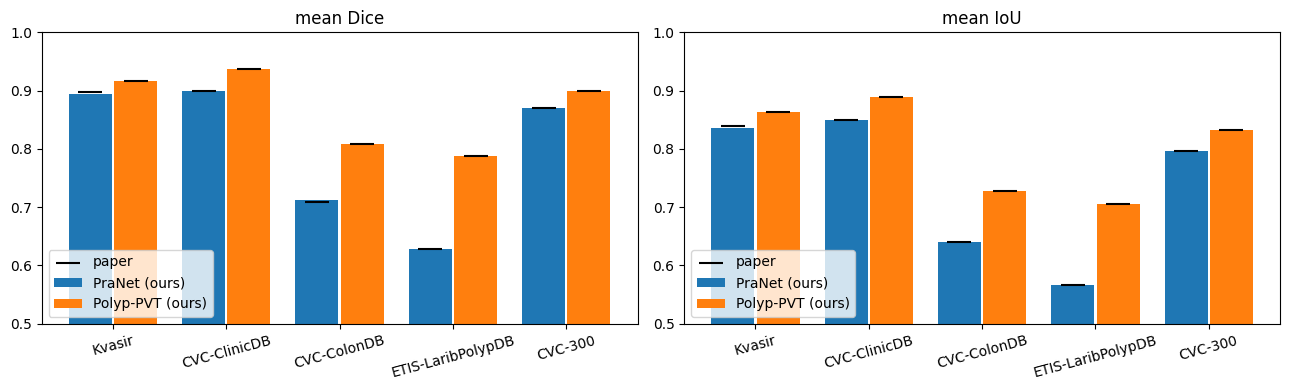

In [17]:
import matplotlib.pyplot as plt

models = [("PraNet", "tab:blue"), ("Polyp-PVT", "tab:orange")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["Dice", "IoU"]):
    x = np.arange(len(DATASETS))
    for k, (model, color) in enumerate(models):
        rows = comparison[comparison.model == model].set_index("dataset").loc[DATASETS]
        offset = (k - 0.5) * 0.4
        ax.bar(x + offset, rows[f"mean{metric}"], 0.38, color=color, label=f"{model} (ours)")
        ax.scatter(x + offset, rows[f"paper_mean{metric}"], color="k", marker="_", s=300, zorder=3,
                   label="paper" if k == 0 else None)
    ax.set_xticks(x)
    ax.set_xticklabels(DATASETS, rotation=15)
    ax.set_ylim(0.5, 1.0)
    ax.set_title(f"mean {metric}")
    ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f"{OUT}/figures/reproduced_vs_paper.png", dpi=200)
plt.show()

Qualitative check: on each dataset, the image where the two models disagree most.

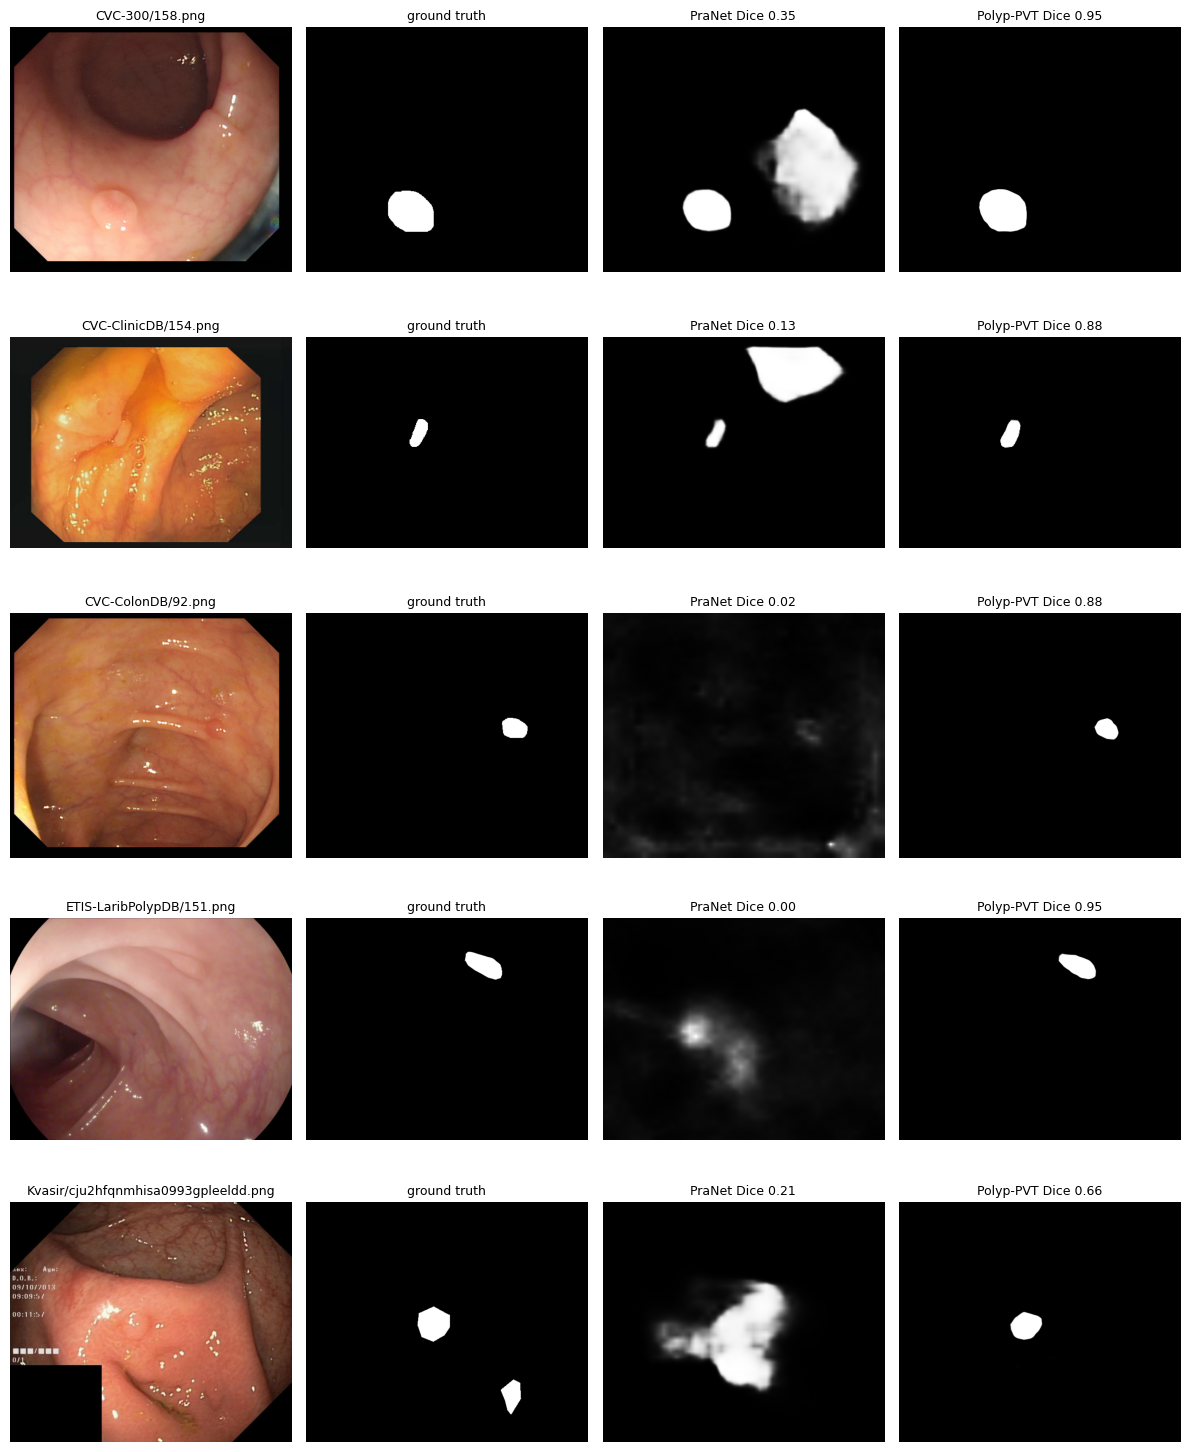

In [18]:
import glob

pranet = pd.read_csv(f"{RESULTS}/PraNet_per_image.csv")
pvt = pd.read_csv(f"{RESULTS}/Polyp-PVT_per_image.csv")
both = pranet.merge(pvt, on=["dataset", "image"], suffixes=("_pranet", "_pvt"))
both["gap"] = (both["dice_mean_thr_pvt"] - both["dice_mean_thr_pranet"]).abs()
worst = both.loc[both.groupby("dataset")["gap"].idxmax()]

fig, axes = plt.subplots(len(worst), 4, figsize=(12, 3 * len(worst)))
for ax_row, (_, row) in zip(axes, worst.iterrows()):
    stem = os.path.splitext(row.image)[0]
    image = cv2.imread(glob.glob(f"{DATA}/TestDataset/{row.dataset}/images/{stem}.*")[0])[:, :, ::-1]
    mask = cv2.imread(glob.glob(f"{DATA}/TestDataset/{row.dataset}/masks/{stem}.*")[0], 0)
    panels = [
        (image, f"{row.dataset}/{row.image}"),
        (mask, "ground truth"),
        (cv2.imread(f"{MAPS}/PraNet/{row.dataset}/{row.image}", 0), f"PraNet Dice {row.dice_mean_thr_pranet:.2f}"),
        (cv2.imread(f"{MAPS}/Polyp-PVT/{row.dataset}/{row.image}", 0), f"Polyp-PVT Dice {row.dice_mean_thr_pvt:.2f}"),
    ]
    for ax, (img, title) in zip(ax_row, panels):
        ax.imshow(img, cmap=None if img.ndim == 3 else "gray")
        ax.set_title(title, fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT}/figures/largest_disagreements.png", dpi=150)
plt.show()

Keep the results, figures and our prediction maps in the work folder (Drive) so they survive the session.

In [19]:
!rm -rf $WORK/m1_out && mkdir -p $WORK/m1_out && cp -r $OUT/results $OUT/figures $MAPS $WORK/m1_out/ && ls $WORK/m1_out $WORK/m1_out/results

/content/drive/MyDrive/polyp-m1/m1_out:
figures  maps  results

/content/drive/MyDrive/polyp-m1/m1_out/results:
authors_maps_check  Polyp-PVT_per_image.csv  PraNet_summary.csv
comparison.csv	    Polyp-PVT_summary.csv
comparison.md	    PraNet_per_image.csv


## Conclusion

Polyp-PVT reproduces the paper on all five test sets, including 0.808 mean Dice on CVC-ColonDB.
PraNet reproduces on four; on Kvasir the released checkpoint gives 0.894 instead of 0.898
(see `milestone1/README.md` for the investigation). Scoring the authors' own maps with this
evaluator returns every paper value, so the metric is the papers' metric: mean Dice over 256
thresholds, which is 0.003–0.009 lower than Dice at a single 0.5 threshold on every set.